# ADA — Official Colab Pretraining Notebook

**This is the only supported Colab entry point for ADA pretraining.** It streams real FineWeb-Edu records, trains ADA from random initialization, evaluates on a held-out stream, and saves resumable checkpoints and metrics to Google Drive.

This is a bounded research pilot, not frontier-scale training. The starter corpus is English-only; do not interpret this run as multilingual or specialist capability.

**Run order:** GPU check → clone current `main` → install dependencies → mount Drive → inspect real records → train → inspect loss and checkpoint.

In [1]:
# 1. Runtime check — in Colab choose Runtime > Change runtime type > T4 GPU (or better)
import torch, os, platform
print('Python:', platform.python_version())
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('GPU is not enabled. In Colab select Runtime > Change runtime type > GPU, then rerun this cell.')
print('GPU:', torch.cuda.get_device_name(0))
print('GPU memory (GiB):', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GiB): 14.56


In [2]:
# 2. Get the latest ADA main branch and install the one required training extra
import os, pathlib, subprocess, sys
REPO_DIR = pathlib.Path('/content/ADA')
if REPO_DIR.exists():
    subprocess.run(['git', '-C', str(REPO_DIR), 'fetch', 'origin'], check=True)
    subprocess.run(['git', '-C', str(REPO_DIR), 'checkout', 'main'], check=True)
    subprocess.run(['git', '-C', str(REPO_DIR), 'pull', '--ff-only', 'origin', 'main'], check=True)
else:
    subprocess.run(['git', 'clone', '--branch', 'main', 'https://github.com/vimalspaceton618-afk/ADA.git', str(REPO_DIR)], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', '.[pretraining]'], cwd=REPO_DIR, check=True)
print('ADA source:', REPO_DIR)
print('Commit:', subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD'], cwd=REPO_DIR, text=True).strip())

ADA source: /content/ADA
Commit: 1489c96


In [3]:
import base64, json, os, pathlib, re, subprocess, sys, tempfile, time
ROOT = pathlib.Path(tempfile.mkdtemp(prefix="ada-validation-", dir="/content"))
REPO = pathlib.Path("/content/ADA")
def evidence(key, value):
    msg = json.dumps({key:value}, ensure_ascii=True).encode()
    print("ADA_RESULT " + base64.b64encode(msg).decode(), flush=True)
def run_capture(key, args):
    start = time.monotonic()
    with (ROOT / (key + ".log")).open("w") as f:
        p = subprocess.run(args, cwd=REPO, stdout=f, stderr=subprocess.STDOUT)
    log = (ROOT / (key + ".log")).read_text(errors="replace")
    log = re.sub(r'https?://[^\s\x27"<>]+', lambda m: m.group().split("?")[0], log)
    evidence(key, dict(exit=p.returncode, seconds=time.monotonic()-start, log=log[-12500:]))
    return p.returncode
evidence("revision", subprocess.check_output(["git","rev-parse","HEAD"], cwd=REPO,text=True).strip())
smoke = ROOT / "smoke"
if run_capture("gpu_smoke", [sys.executable,"scripts/ada_gpu_smoke_test.py","--device","cuda","--steps","3","--batch-size","1","--sequence-length","16","--output-dir",str(smoke)]) == 0:
    evidence("gpu_smoke_report", json.loads((smoke/"report.json").read_text()))
    realdir = ROOT / "real"
    pilot_cmd = [sys.executable,"scripts/ada_pretrain_fineweb_edu.py","--device","cuda","--max-steps","3","--batch-size","1","--sequence-length","16","--vocab-size","320","--tokenizer-docs","8","--eval-every","1","--save-every","1","--eval-batches","1"]
    if run_capture("gpu_fineweb", pilot_cmd + ["--output-dir",str(realdir)]) == 0:
        evidence("gpu_fineweb_summary",json.loads((realdir/"run_summary.json").read_text()))
        evidence("gpu_fineweb_metrics",[json.loads(x) for x in (realdir/"metrics.jsonl").read_text().splitlines()])


ADA_RESULT eyJyZXZpc2lvbiI6ICIxNDg5Yzk2ZTU2MzZjYWIxNjQxYWMxMDhmODk2NjhjYmU1ZWRmMDE1In0=
ADA_RESULT eyJncHVfc21va2UiOiB7ImV4aXQiOiAwLCAic2Vjb25kcyI6IDExLjc1NjEzMzE2Njk5OTk3MywgImxvZyI6ICJcbj09PT09PT09PT0gQURBIEdQVSBTTU9LRSBURVNUOiBQQVNTID09PT09PT09PT1cbkRldmljZTogICAgICAgICAgVGVzbGEgVDRcblB5VG9yY2ggLyBDVURBOiAgMi4xNC4xK2N1MTMwIC8gMTMuMFxuQXJjaGl0ZWN0dXJlOiAgICBNYW1iYTJSZWZlcmVuY2VNaXhlciwgVGVuc29yTmV0QXR0ZW50aW9uLCBNYW1iYTJSZWZlcmVuY2VNaXhlciwgVGVuc29yTmV0QXR0ZW50aW9uXG5QYXJhbWV0ZXJzOiAgICAgIDIsMjk1LDc2OFxuU3RlcHM6ICAgICAgICAgICAzXG5GaW5hbCBsb3NzOiAgICAgIDcuMzU0MTUwXG5NYW1iYSB1cGRhdGU6ICAgIDMuMDA3NTc1ODdlLTA0XG5FbGFwc2VkOiAgICAgICAgIDEuNjBzXG5UaHJvdWdocHV0OiAgICAgIDMwLjAzIHN5bnRoZXRpYyB0b2tlbnMvcyAodHJhaW4gc3RlcClcblBlYWsgR1BVIG1lbW9yeTogNjAuNjEgTWlCXG5SZXBvcnQ6ICAgICAgICAgIC9jb250ZW50L2FkYS12YWxpZGF0aW9uLXl0cV9nNGoxL3Ntb2tlL3JlcG9ydC5qc29uXG5CdW5kbGU6ICAgICAgICAgIC9jb250ZW50L2FkYS12YWxpZGF0aW9uLXl0cV9nNGoxL3Ntb2tlL2FkYV9ncHVfc21va2VfdGVzdF9idW5kbGUuemlwXG49PT09PT09PT09PT09PT09PT09PT09P

In [5]:
import importlib.metadata, json, re, pathlib, sys, subprocess, os, time
from ada.atomic_checkpoint import resolve_committed_checkpoint
evidence("gpu_fineweb_summary",json.loads((realdir/"run_summary.json").read_text()))
evidence("gpu_fineweb_metrics",[json.loads(x) for x in (realdir/"metrics.jsonl").read_text().splitlines()])
evidence("gpu_pilot_verified_snapshot",resolve_committed_checkpoint(realdir).name)
evidence("gpu_packages",{k:importlib.metadata.version(k) for k in ["torch","datasets","pyarrow","huggingface-hub","fsspec","tokenizers","pandas","matplotlib"]})
RUN_DIR=ROOT/"notebook-defaults"
RUN_DIR.mkdir(exist_ok=False)
evidence("notebook_output_dir",str(RUN_DIR))

ModuleNotFoundError: No module named 'ada'

In [6]:
import importlib.metadata, json, re, pathlib, sys, subprocess, os, time
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0,str(REPO_DIR))
from ada.atomic_checkpoint import resolve_committed_checkpoint
evidence("gpu_fineweb_summary",json.loads((realdir/"run_summary.json").read_text()))
evidence("gpu_fineweb_metrics",[json.loads(x) for x in (realdir/"metrics.jsonl").read_text().splitlines()])
evidence("gpu_pilot_verified_snapshot",resolve_committed_checkpoint(realdir).name)
evidence("gpu_packages",{k:importlib.metadata.version(k) for k in ["torch","datasets","pyarrow","huggingface-hub","fsspec","tokenizers","pandas","matplotlib"]})
RUN_DIR=ROOT/"notebook-defaults"
RUN_DIR.mkdir(exist_ok=False)
evidence("notebook_output_dir",str(RUN_DIR))

ADA_RESULT eyJncHVfZmluZXdlYl9zdW1tYXJ5IjogeyJzdGF0dXMiOiAiQ09NUExFVEVEIiwgInJ1bl90eXBlIjogInJlYWxfZGF0YV9jYXVzYWxfbG1fcHJldHJhaW5pbmciLCAiZGF0YXNldF9pZCI6ICJIdWdnaW5nRmFjZUZXL2ZpbmV3ZWItZWR1IiwgImRhdGFzZXRfY29uZmlnIjogInNhbXBsZS0xMEJUIiwgImRhdGFzZXRfcmV2aXNpb24iOiAiODdmMDkxNDllZjQ3MzQyMDRkNzBlZDFkMDQ2ZGRjOWNhM2YyYjhmOSIsICJkZXZpY2UiOiAiY3VkYSIsICJncHVfbmFtZSI6ICJUZXNsYSBUNCIsICJwcmVjaXNpb24iOiAiZmxvYXQzMiIsICJwYXJhbWV0ZXJzX3RvdGFsIjogMjA2MDM3NiwgInN0ZXBzX3RoaXNfc2Vzc2lvbiI6IDMsICJ0YXJnZXRfc3RlcHMiOiAzLCAidG9rZW5zX3RoaXNfc2Vzc2lvbiI6IDQ4LCAidG9rZW5zX3NlZW5fdG90YWwiOiA0OCwgImVsYXBzZWRfc2Vjb25kcyI6IDE1LjQ2LCAidG9rZW5zX3Blcl9zZWNvbmQiOiAzLjEsICJ2YWxpZGF0aW9uX2xvc3NfYXRfc2Vzc2lvbl9zdGFydCI6IDUuODMwNjY3NDk1NzI3NTM5LCAibGF0ZXN0X3ZhbGlkYXRpb25fbG9zcyI6IDUuODI0NTI4MjE3MzE1Njc0LCAicGVha19jdWRhX21lbW9yeV9taWIiOiA1NS43MywgImNoZWNrcG9pbnRfZGlyIjogIi9jb250ZW50L2FkYS12YWxpZGF0aW9uLXl0cV9nNGoxL3JlYWwvY2hlY2twb2ludHMvc3RlcC0wMDAwMDAwMDAwMDMtYjljNTI3Mjg2NjU1NDM4Njk5ZmIxZGM0YzM4YWNmZTcvbW9kZWwiLCAibWV0c

In [4]:
# 3. Mount Google Drive — all training artifacts are written here, not to ephemeral /content
from google.colab import drive
drive.mount('/content/drive')
DRIVE_ROOT = pathlib.Path('/content/drive/MyDrive/ADA_Pretraining')
RUN_DIR = DRIVE_ROOT / 'fineweb_edu_pilot'
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Persistent run directory:', RUN_DIR)
print('Existing files:', [p.name for p in RUN_DIR.iterdir()])

MessageError: Error: credential propagation was unsuccessful

In [7]:
# 4. Inspect real training-corpus records before starting
from datasets import load_dataset
from pprint import pprint
preview = load_dataset('HuggingFaceFW/fineweb-edu', name='sample-10BT', split='train', streaming=True, revision='87f09149ef4734204d70ed1d046ddc9ca3f2b8f9')
for i, row in enumerate(preview.take(3), start=1):
    print(f'--- RECORD {i} ---')
    pprint({k: v for k, v in row.items() if k != 'text'})
    print((row.get('text') or '')[:1200], '\\n')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

--- RECORD 1 ---
{'dump': 'CC-MAIN-2013-20',
 'file_path': 's3://commoncrawl/crawl-data/CC-MAIN-2013-20/segments/1368696381249/warc/CC-MAIN-20130516092621-00000-ip-10-60-113-184.ec2.internal.warc.gz',
 'id': '<urn:uuid:0d8a309d-25c5-405d-a08a-c11239f0d717>',
 'int_score': 3,
 'language': 'en',
 'language_score': 0.9743200540542603,
 'score': 2.75,
 'token_count': 845,
 'url': 'http://austenauthors.net/the-independent-jane'}
The Independent Jane
For all the love, romance and scandal in Jane Austen’s books, what they are really about is freedom and independence. Independence of thought and the freedom to choose.
Elizabeth’s refusal of Mr. Collins offer of marriage showed an independence seldom seen in heroines of the day. Her refusal of Mr. Darcy while triggered by anger showed a level of independence that left him shocked and stunned.
The freedom she exhibited in finally accepting him in direct defiance of Lady Catherine and knowing her father would disapprove was unusual even for Auste

## Training configuration

The defaults below run **500 optimizer steps × batch 4 × sequence length 256 = 512,000 next-token targets**. Start with these settings and inspect actual GPU memory and validation behavior.

New single-process runs save immutable snapshots under `RUN_DIR/checkpoints/step-...` and publish `checkpoints/latest.json` only after saving and checksum verification. Set `RESUME = True` after a saved checkpoint to restore model, optimizer and RNG state, then replay the consumed streaming batches. An interrupted save should leave the previous published pointer intact.

**Storage limitation:** Directory rename/flush durability on Google Drive's FUSE mount is not equivalent to local POSIX filesystem guarantees. Until Colab disconnection fault tests pass, keep independent backups of published checkpoints. No claim is made for multi-node or GPU-distributed atomicity.


In [8]:
# 5. Launch actual real-data pretraining (not a synthetic smoke test)
MAX_STEPS = 500
BATCH_SIZE = 4
SEQUENCE_LENGTH = 256
VOCAB_SIZE = 8192
TOKENIZER_DOCS = 20000
RESUME = False  # Change to True only to continue this exact run from its saved checkpoint
args = [
    sys.executable, 'scripts/ada_pretrain_fineweb_edu.py',
    '--device', 'cuda', '--output-dir', str(RUN_DIR),
    '--max-steps', str(MAX_STEPS), '--batch-size', str(BATCH_SIZE),
    '--sequence-length', str(SEQUENCE_LENGTH), '--vocab-size', str(VOCAB_SIZE),
    '--tokenizer-docs', str(TOKENIZER_DOCS), '--eval-every', '100',
    '--eval-batches', '8', '--save-every', '50'
]
if RESUME:
    args.append('--resume')
print('Command:', ' '.join(args))
subprocess.run(args, cwd=REPO_DIR, check=True)

Command: /usr/bin/python3 scripts/ada_pretrain_fineweb_edu.py --device cuda --output-dir /content/ada-validation-ytq_g4j1/notebook-defaults --max-steps 500 --batch-size 4 --sequence-length 256 --vocab-size 8192 --tokenizer-docs 20000 --eval-every 100 --eval-batches 8 --save-every 50


CompletedProcess(args=['/usr/bin/python3', 'scripts/ada_pretrain_fineweb_edu.py', '--device', 'cuda', '--output-dir', '/content/ada-validation-ytq_g4j1/notebook-defaults', '--max-steps', '500', '--batch-size', '4', '--sequence-length', '256', '--vocab-size', '8192', '--tokenizer-docs', '20000', '--eval-every', '100', '--eval-batches', '8', '--save-every', '50'], returncode=0)

,step,tokens_seen,train_loss,validation_loss,event,learning_rate,elapsed_seconds
0,0,0,NaN,9.031515,initial_validation,NaN,NaN
1,100,102400,8.278689,7.451259,NaN,2.823904e-04,15.87
2,200,204800,7.341161,7.223579,NaN,2.111615e-04,28.01
3,300,307200,7.122598,7.161024,NaN,1.141397e-04,38.17
4,400,409600,7.168875,7.094944,NaN,3.224086e-05,48.00
5,500,512000,7.232445,7.083436,NaN,3.280743e-09,57.60


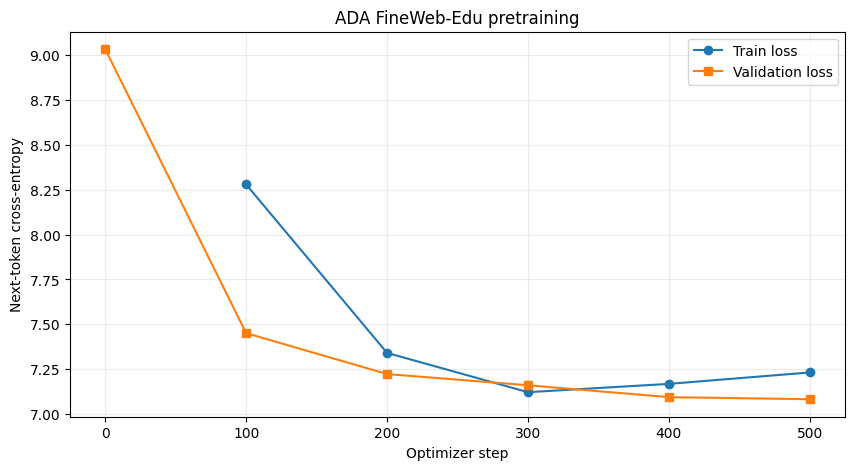

In [9]:
# 6. Plot the actual training and held-out validation metrics
import json, pandas as pd, matplotlib.pyplot as plt
metrics_path = RUN_DIR / 'metrics.jsonl'
if not metrics_path.exists():
    raise FileNotFoundError(f'Metrics not found: {metrics_path}')
rows = [json.loads(line) for line in metrics_path.read_text().splitlines() if line.strip()]
metrics = pd.DataFrame(rows)
display(metrics.tail(10))
plt.figure(figsize=(10, 5))
if 'train_loss' in metrics:
    train = metrics.dropna(subset=['train_loss'])
    if len(train): plt.plot(train['step'], train['train_loss'], marker='o', label='Train loss')
valid = metrics.dropna(subset=['validation_loss'])
if len(valid): plt.plot(valid['step'], valid['validation_loss'], marker='s', label='Validation loss')
plt.xlabel('Optimizer step'); plt.ylabel('Next-token cross-entropy'); plt.title('ADA FineWeb-Edu pretraining')
plt.grid(True, alpha=0.25); plt.legend(); plt.show()

In [10]:
# 7. Verify the latest published snapshot, model and optimizer artifacts
from ada.atomic_checkpoint import resolve_committed_checkpoint, REQUIRED_FILES

snapshot = resolve_committed_checkpoint(RUN_DIR)
if snapshot is None:
    print('No versioned checkpoint pointer found; checking legacy run directory.')
    snapshot = RUN_DIR
else:
    print('Published verified snapshot:', snapshot)

for name in ['run_summary.json', 'run_manifest.json']:
    path = (RUN_DIR / name) if name == 'run_summary.json' else (snapshot / name)
    print(f'\\n===== {name} =====')
    if path.exists(): print(path.read_text())
    else: print('Not present — training may not have completed or saved.')

for relative in REQUIRED_FILES:
    path = snapshot / relative
    print(('OK  ' if path.is_file() else 'MISS'), path,
          (f'{path.stat().st_size:,} bytes' if path.is_file() else ''))

print('Last validated published directory:', snapshot)
print('Train/evaluation metrics:', RUN_DIR / 'metrics.jsonl')


Published verified snapshot: /content/ada-validation-ytq_g4j1/notebook-defaults/checkpoints/step-000000000500-fe232f8487084509952fc688b1bd9d87
\n===== run_summary.json =====
{
  "status": "COMPLETED",
  "run_type": "real_data_causal_lm_pretraining",
  "dataset_id": "HuggingFaceFW/fineweb-edu",
  "dataset_config": "sample-10BT",
  "dataset_revision": "87f09149ef4734204d70ed1d046ddc9ca3f2b8f9",
  "device": "cuda",
  "gpu_name": "Tesla T4",
  "precision": "float32",
  "parameters_total": 3098712,
  "steps_this_session": 500,
  "target_steps": 500,
  "tokens_this_session": 512000,
  "tokens_seen_total": 512000,
  "elapsed_seconds": 58.02,
  "tokens_per_second": 8824.19,
  "validation_loss_at_session_start": 9.031514644622803,
  "latest_validation_loss": 7.0834362506866455,
  "peak_cuda_memory_mib": 245.88,
  "checkpoint_dir": "/content/ada-validation-ytq_g4j1/notebook-defaults/checkpoints/step-000000000500-fe232f8487084509952fc688b1bd9d87/model",
  "metrics_file": "/content/ada-validation-

## What this run does — and does not — establish

- It trains ADA weights from random initialization on streamed, real FineWeb-Edu records.
- It records training/validation loss, tokens seen, run configuration, and resumable checkpoints.
- FineWeb-Edu is English educational web text. It is not an India-language mixture, code corpus, cybersecurity corpus, or balanced domain dataset.
- A falling loss is evidence of optimization on this corpus, not proof of reasoning, safety, general intelligence, or frontier capability.
- Review the dataset card and applicable terms before redistribution: https://huggingface.co/datasets/HuggingFaceFW/fineweb-edu

**Next gate:** inspect the completed `run_summary.json`, validation curve, tokens/sec, and GPU memory before selecting a larger run or adding multilingual/domain data.